# Dữ liệu ảnh — hoá đơn điện tử (EDA cấu trúc, không lộ dữ liệu nhạy cảm)

**Nhóm T&D** · Trần Hữu Anh Triết (2470745), Ngô Minh Đại (2470722)

**Học phần:** Nền tảng lập trình cho phân tích và trực quan dữ liệu · Học kỳ 261, năm học 2026–2027 · Giảng viên Lê Thành Sách

Checkpoint này khảo sát **cấu trúc ảnh hoá đơn điện tử** để chuẩn bị cho bài toán phân loại/kiểm tra ảnh. Vì hoá đơn chứa **thông tin nhạy cảm** (mã số thuế, tên công ty, số tiền), repo công khai **không chứa ảnh gốc**; notebook chỉ dùng **đặc trưng số và toạ độ đã trích sẵn** (`notebooks/data/invoice_features.csv`, `invoice_blocks.csv`). Nhờ vậy Run-all trên Colab tái lập được mọi biểu đồ mà không cần ảnh và không lộ dữ liệu.

## 1. Bài toán và phạm vi checkpoint

Hướng tới **phân loại/kiểm tra ảnh hoá đơn điện tử** (ví dụ: có mã / không mã cơ quan thuế; có / không chữ ký số; hợp lệ / nghi ngờ). Checkpoint này làm **EDA cấu trúc ảnh**: độ phân giải, màu, vùng chữ ký số, mã QR, và bố cục khối văn bản — những đặc trưng mà mô hình ảnh sẽ dùng.

> **Hạn chế trung thực:** đề yêu cầu ≥ 5.000 ảnh và ≥ 3 lớp. Tập hiện có **2 hoá đơn BPOS** — đây là *bước khởi đầu pipeline*, chưa đủ quy mô. Mục 3 nêu rõ khoảng cách và kế hoạch mở rộng.

## 2. Dữ liệu

- Nguồn: hoá đơn điện tử của **BPOS** (bên mua). Không dùng hoá đơn của bên thứ ba.
- **Không commit ảnh gốc** lên repo công khai (bảo mật MST, tên công ty, số tiền).
- Chỉ commit **đặc trưng đã trích**: mỗi hoá đơn một dòng số liệu; mỗi khối văn bản một dòng toạ độ chuẩn hoá (0..1) — không chứa nội dung chữ.
- Trích bằng `PyMuPDF` + `OpenCV` (xem cell "trích đặc trưng" ở cuối, chỉ chạy cục bộ khi có PDF).

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib
import matplotlib.patches as mpatches
import seaborn as sns
sns.set_theme(style="whitegrid"); plt.rcParams["figure.dpi"] = 110
matplotlib.rcParams["font.family"] = "DejaVu Sans"

BASE_LOCAL = "data/"
BASE_RAW = "https://raw.githubusercontent.com/tobitran17-art/CO5177/main/notebooks/data/"
def load(name):
    try:
        return pd.read_csv(BASE_LOCAL + name)
    except FileNotFoundError:
        return pd.read_csv(BASE_RAW + name)
feat = load("invoice_features.csv")
blocks = load("invoice_blocks.csv")
print("Hoá đơn:", len(feat), "| text-block:", len(blocks))
feat

Hoá đơn: 2 | text-block: 107


,invoice,width_px,height_px,aspect,n_pages,mean_saturation,mean_brightness,green_stamp_ratio,has_qr,dark_pixel_ratio,edge_density,n_text_blocks,stamp_x,stamp_y,stamp_w,stamp_h,qr_x,qr_y,qr_w,qr_h
0,bpos_01,1656,2342,1.414,1,4.75,241.5,0.0121,1,0.0608,0.0550,35,0.0441,0.0222,0.9124,0.8992,0.0827,0.1524,0.0972,0.0687
1,bpos_02,1653,2339,1.415,1,2.30,241.1,0.0006,0,0.0612,0.0556,72,0.7562,0.8029,0.0605,0.0295,0.0000,0.0000,0.0000,0.0000


## 3. Đối chiếu ràng buộc (và khoảng cách)

Nêu rõ phần đã có và phần còn thiếu so với đề.

In [2]:
chk = pd.DataFrame([
    ["Số ảnh", "≥ 5.000", f"{len(feat)} (khởi đầu)", "Chưa — cần thu thập thêm"],
    ["Số lớp", "≥ 3", "chưa gán nhãn lớp", "Chưa"],
    ["Độ phân giải", "cạnh ngắn ≥ 128 px", f"cạnh ngắn ~{int(feat['width_px'].min())} px", "Đạt"],
    ["Không lộ PII", "repo public", "chỉ đặc trưng số", "Đạt"],
], columns=["Tiêu chí", "Yêu cầu", "Hiện tại", "Trạng thái"])
chk

,Tiêu chí,Yêu cầu,Hiện tại,Trạng thái
0,Số ảnh,≥ 5.000,2 (khởi đầu),Chưa — cần thu thập thêm
1,Số lớp,≥ 3,chưa gán nhãn lớp,Chưa
2,Độ phân giải,cạnh ngắn ≥ 128 px,cạnh ngắn ~1653 px,Đạt
3,Không lộ PII,repo public,chỉ đặc trưng số,Đạt


**Kế hoạch mở rộng để đạt ≥ 5.000 ảnh / ≥ 3 lớp:** thu thập thêm hoá đơn điện tử (ẩn danh hoá PII trước khi lưu), gán nhãn theo tiêu chí có ý nghĩa nghiệp vụ — ví dụ **có mã / không mã cơ quan thuế**, **có / không chữ ký số (dấu xanh)**, **có / không QR** — và cân nhắc augmentation hợp lý (xoay nhẹ, nhiễu scan, thay đổi độ sáng) để mô phỏng ảnh chụp/scan thực tế.

## 4. Thuộc tính ảnh

Hoá đơn điện tử render ra ảnh gần như **trắng** (độ bão hoà rất thấp, độ sáng cao), tỉ lệ A4 dọc. Đây là đặc điểm giúp phân biệt với ảnh chụp giấy.

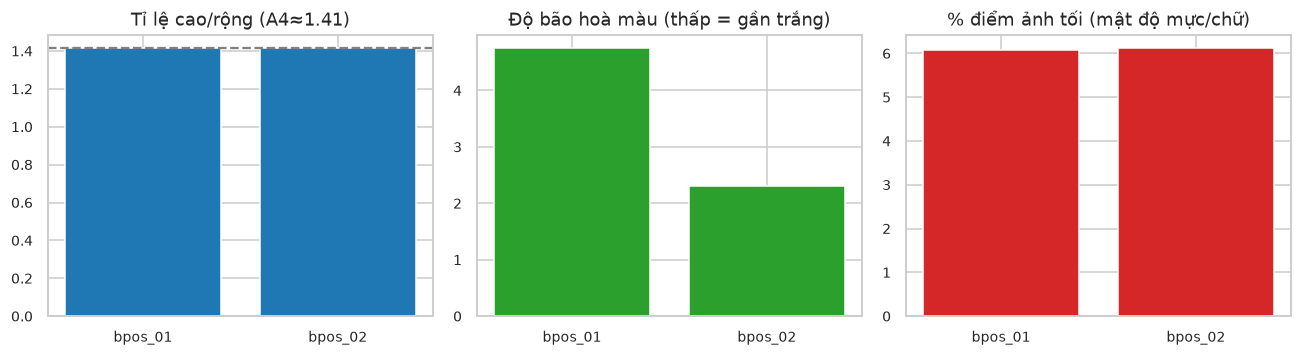

Kết luận: ảnh dạng tài liệu (nền trắng, tỉ lệ A4). bpos_02 nhiều chữ hơn -> %%điểm tối và số text-block cao hơn.


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
axes[0].bar(feat["invoice"], feat["aspect"], color="#1f77b4"); axes[0].set_title("Tỉ lệ cao/rộng (A4≈1.41)"); axes[0].axhline(1.414, ls="--", c="gray")
axes[1].bar(feat["invoice"], feat["mean_saturation"], color="#2ca02c"); axes[1].set_title("Độ bão hoà màu (thấp = gần trắng)")
axes[2].bar(feat["invoice"], feat["dark_pixel_ratio"]*100, color="#d62728"); axes[2].set_title("% điểm ảnh tối (mật độ mực/chữ)")
for ax in axes: ax.tick_params(labelsize=9)
plt.tight_layout(); plt.show()
print("Kết luận: ảnh dạng tài liệu (nền trắng, tỉ lệ A4). bpos_02 nhiều chữ hơn -> %%điểm tối và số text-block cao hơn.")

## 5. Dấu chữ ký số và mã QR — đặc trưng nhận biết hoá đơn điện tử

Phần mềm hoá đơn thường vẽ **con dấu chữ ký số màu xanh** và/hoặc **mã QR**. Tỉ lệ vùng xanh và sự hiện diện QR là đặc trưng rẻ, dễ tính, giúp phân biệt mẫu phát hành.

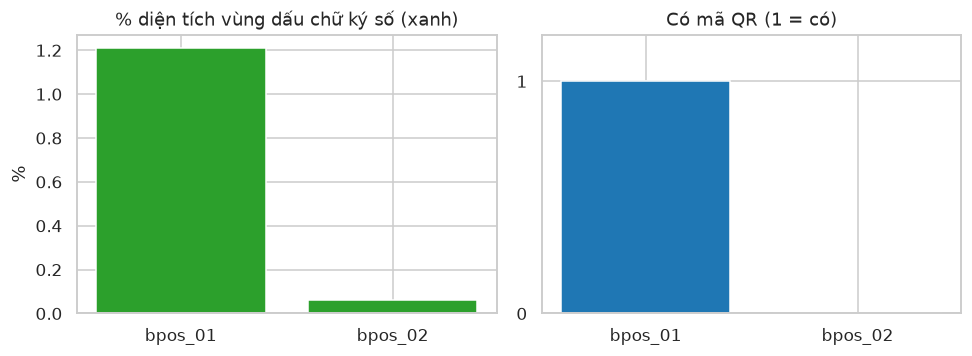

Kết luận: bpos_01 có dấu chữ ký số (1.2%% vùng xanh) và QR; bpos_02 gần như không có vùng xanh và không QR
-> ngay 2 mẫu đã khác nhau rõ, hợp làm tiêu chí gán nhãn khi mở rộng tập.


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
axes[0].bar(feat["invoice"], feat["green_stamp_ratio"]*100, color="#2ca02c")
axes[0].set_title("% diện tích vùng dấu chữ ký số (xanh)"); axes[0].set_ylabel("%")
axes[1].bar(feat["invoice"], feat["has_qr"], color="#1f77b4")
axes[1].set_title("Có mã QR (1 = có)"); axes[1].set_ylim(0, 1.2); axes[1].set_yticks([0,1])
plt.tight_layout(); plt.show()
print("Kết luận: bpos_01 có dấu chữ ký số (1.2%% vùng xanh) và QR; bpos_02 gần như không có vùng xanh và không QR")
print("-> ngay 2 mẫu đã khác nhau rõ, hợp làm tiêu chí gán nhãn khi mở rộng tập.")

## 6. Bố cục khối văn bản (layout)

Vẽ lại **bản đồ khối** từ toạ độ đã trích (không có nội dung chữ): hình chữ nhật xám là khối văn bản, khung xanh là vùng dấu chữ ký số, khung xanh dương là QR. Cho thấy cấu trúc trang hoá đơn mà không lộ dữ liệu.

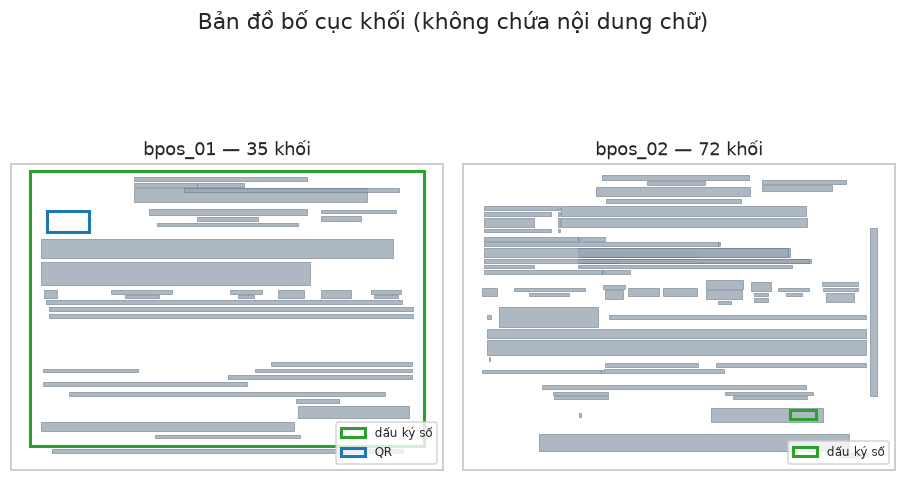

Kết luận: cấu trúc gần giống nhau (khối tiêu đề trên, bảng hàng hoá giữa, tổng tiền + dấu ký số dưới) -> layout là đặc trưng ổn định.


In [5]:
invs = list(feat["invoice"])
fig, axes = plt.subplots(1, len(invs), figsize=(4.2*len(invs), 5.4))
if len(invs) == 1: axes = [axes]
for ax, inv in zip(axes, invs):
    r = feat[feat.invoice==inv].iloc[0]
    for _, b in blocks[blocks.invoice==inv].iterrows():
        ax.add_patch(mpatches.Rectangle((b.x, b.y), b.w, b.h, facecolor="#9aa7b5", edgecolor="#5b6b7b", lw=0.4, alpha=0.8))
    if r.stamp_w > 0:
        ax.add_patch(mpatches.Rectangle((r.stamp_x, r.stamp_y), r.stamp_w, r.stamp_h, fill=False, edgecolor="#2ca02c", lw=2, label="dấu ký số"))
    if r.qr_w > 0:
        ax.add_patch(mpatches.Rectangle((r.qr_x, r.qr_y), r.qr_w, r.qr_h, fill=False, edgecolor="#1f77b4", lw=2, label="QR"))
    ax.set_xlim(0,1); ax.set_ylim(1,0); ax.set_aspect(r.width_px/r.height_px)
    ax.set_title(f"{inv} — {int(r.n_text_blocks)} khối"); ax.set_xticks([]); ax.set_yticks([])
    h,l = ax.get_legend_handles_labels()
    if h: ax.legend(fontsize=8, loc="lower right")
fig.suptitle("Bản đồ bố cục khối (không chứa nội dung chữ)")
plt.tight_layout(); plt.show()
print("Kết luận: cấu trúc gần giống nhau (khối tiêu đề trên, bảng hàng hoá giữa, tổng tiền + dấu ký số dưới) -> layout là đặc trưng ổn định.")

## 7. Phân phối khối văn bản (gộp các hoá đơn)

Gộp 107 khối từ các hoá đơn để nhìn phân phối kích thước và vị trí — dữ liệu phong phú hơn số lượng ảnh.

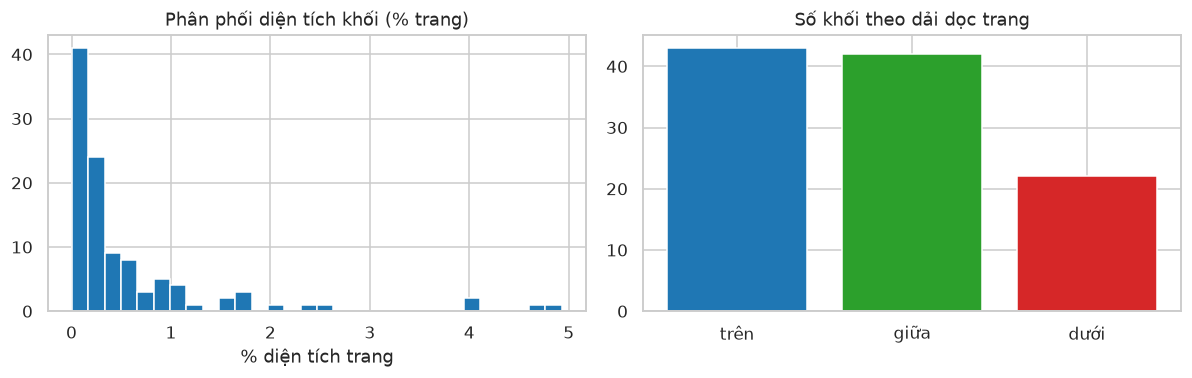

Kết luận: đa số khối nhỏ (<1%% trang) = dòng chữ; khối lớn = bảng/tiêu đề. Khối tập trung nửa trên (thông tin bên bán/mua).


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].hist(blocks["area"]*100, bins=30, color="#1f77b4")
axes[0].set_title("Phân phối diện tích khối (% trang)"); axes[0].set_xlabel("% diện tích trang")
band_order = ["trên", "giữa", "dưới"]
bc = blocks["band"].value_counts().reindex(band_order)
axes[1].bar(band_order, bc.values, color=["#1f77b4", "#2ca02c", "#d62728"])
axes[1].set_title("Số khối theo dải dọc trang")
plt.tight_layout(); plt.show()
print("Kết luận: đa số khối nhỏ (<1%% trang) = dòng chữ; khối lớn = bảng/tiêu đề. Khối tập trung nửa trên (thông tin bên bán/mua).")

## 8. Nhận xét và phần sau

- Ảnh hoá đơn là **tài liệu nền trắng, tỉ lệ A4**; đặc trưng rẻ (bão hoà, % tối, số khối, vùng xanh, QR) đã **phân biệt được 2 mẫu**.
- **Dấu chữ ký số (vùng xanh)** và **QR** là tiêu chí gán nhãn tiềm năng khi mở rộng tập.
- Bố cục khối ổn định (tiêu đề trên, bảng giữa, tổng + dấu dưới) → đặc trưng layout hữu ích.
- **Hạn chế:** mới 2 ảnh, chưa đạt ≥ 5.000 / ≥ 3 lớp.

**Phần sau (checkpoint tiếp):** thu thập thêm hoá đơn (ẩn danh PII), gán nhãn theo tiêu chí nghiệp vụ, chia train/val/test tránh rò rỉ, trích đặc trưng bằng mô hình **pretrained** (feature extractor) so với đặc trưng thủ công (OpenCV), và **confusion matrix kèm mẫu bị gán sai**.

---
*Cell dưới chỉ chạy cục bộ (khi có PDF gốc) để tạo lại hai file CSV; trên Colab sẽ bỏ qua.*

In [7]:
# Trích đặc trưng từ PDF -> CSV (chỉ số & toạ độ, KHÔNG xuất nội dung chữ).
# Chạy cục bộ khi có thư mục chứa hoá đơn gốc; trên Colab (không có file) sẽ bỏ qua.
import os
PDF_DIR = os.environ.get("INVOICE_PDF_DIR", "")   # ví dụ: đặt biến môi trường trỏ tới thư mục PDF cục bộ
if PDF_DIR and os.path.isdir(PDF_DIR):
    print("Có PDF — chạy script trích đặc trưng cục bộ (xem repo nội bộ). Bỏ qua ở đây để không phụ thuộc ảnh gốc.")
else:
    print("Không có PDF gốc (môi trường công khai/Colab) — dùng CSV đã commit. Đây là hành vi mong muốn.")

Không có PDF gốc (môi trường công khai/Colab) — dùng CSV đã commit. Đây là hành vi mong muốn.
